# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import sys
import os
import random
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.stats import skew

import torch
from torch.utils.tensorboard import SummaryWriter
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import gradio as gr

### 0.1. Перевіряємо середовище виконання

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

Running in Colab: False


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Seed зафіксовано:", SEED)

Seed зафіксовано: 42


### 0.3. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cpu


### 0.4. Налаштування директорій для збереження артефактів

Створюємо директорії `models/` та `runs/` для збереження чекпоінтів моделей (`.pt`), логів TensorBoard і таблиці `results.csv` відповідно до вимог структури репозиторію (`/lab2/`).

In [5]:
ARTIFACT_DIR = "."
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", os.path.abspath(ARTIFACT_DIR))
print("Папка моделей:", os.path.abspath(MODELS_DIR))
print("Папка логів TensorBoard:", os.path.abspath(RUNS_DIR))

Артефакти зберігаються в: /lab2
Папка моделей: /lab2/models
Папка логів TensorBoard: /lab2/runs


## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.5. Мої відповіді:

1. **Чому для заповнення пропусків було обрано метод kNN?**
   - Якщо просто видалити рядки з пропусками (`dropna`), ми втратимо близько 10% даних.
   - Якщо заповнити медіаною чи середнім, у всі пропуски підставиться одне й те саме число без урахування інших характеристик будинку.
   - **Метод kNN** знаходить 5 найбільш схожих будинків (за доходом району, віком, координатами тощо) і бере середнє значення по них. Це дає набагато точніший результат. А щоб уникнути витоку даних (*data leakage*), kNN навчається лише на `train`, а потім застосовується до `val` і `test`.

2. **Чому при тренуванні лінійної регресії `train` і `val` порівнюються лише на основі MSE, а після тренування — на основі багатьох функцій? Експеримент із вибором функції втрат.**
   - **Під час тренування** градієнтному спуску потрібна одна гладка функція втрат (`MSELoss`), щоб рахувати похідні (градієнти) і оновлювати ваги моделі. На `val` рахують ту саму MSE, щоб порівнювати `train` і `val` в одній шкалі й бачити, чи немає перенавчання.
   - **Після тренування** на `test` ми дивимося на кілька метрик, бо кожна показує свою сторону якості: **MSE** сильно штрафує за великі промахи, **RMSE** показує помилку в реальних одиницях (доларах), **MAE** дає середню похибку без надмірного впливу викидів, а **$R^2$** показує, яку частку дисперсії пояснює модель (від 0 до 1).
   - **Результати експерименту (клітинка 0.6 нижче):** ми порівняли навчання з `MSELoss`, `L1Loss` (MAE) та `HuberLoss`. Навчання з `MSELoss` дало найкращі **MSE, RMSE та $R^2$**, а `L1Loss` та `HuberLoss` показали трохи меншу середню абсолютну помилку (**MAE**), бо вони менше реагують на викиди.

3. **Які висновки після клітинки 2.6 в демо Ви можете зробити?**
   - Оскільки ознаки стандартизовані, величина ваги показує важливість кожної ознаки:
     1. **`MedInc` (дохід)** має найбільшу вагу — це головний фактор ціни житла.
     2. **Нові ознаки `diag_coord` і `bedperroom`** зайняли 2-ге і 3-тє місця за впливом. Це підтверджує, що інженерія ознак у п. 1.8 справді допомогла моделі.
     3. **`Population` та `AveOccup`** мають майже нульові ваги: населення майже не корелює з ціною, а в `AveOccup` через величезні викиди (до 1243 осіб) стандартне відхилення сильно розтягнулося, стиснувши звичайні значення до нуля.

4. **Для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?**
   - **Baseline у лінійній регресії** — це найпростіший орієнтир, коли модель для всіх об'єктів просто передбачає середнє значення цільової змінної з `train` ($\bar{y}_{\text{train}}$, для якого $R^2 \approx 0$). Якщо лінійна регресія працює не краще за просте середнє, значить вона нічого не навчилася.
   - **Baseline для нейронної мережі** — це вже навчена **лінійна регресія**. Нейромережа набагато складніша й довше навчається, тому її є сенс використовувати лише тоді, коли вона дає відчутно кращі метрики на `test`, ніж проста лінійна модель.

5. **Дія всіх функцій активації на графіку (1000 випадкових значень X):**
   - Побудовано у клітинці **0.7** нижче для функцій **ReLU**, **Leaky ReLU**, **Sigmoid** та **Tanh**.

6. **Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?**
   - На вхід подається $7$ ознак. У кожному лінійному шарі кількість параметрів дорівнює $\text{входи} \times \text{виходи} + \text{зміщення (bias)}$, а шари `ReLU` параметрів не мають:
     - `Linear(7 → 64)`: $7 \times 64 + 64 = 512$
     - `Linear(64 → 32)`: $64 \times 32 + 32 = 2080$
     - `Linear(32 → 1)`: $32 \times 1 + 1 = 33$
   - **Разом:** $512 + 2080 + 33 = \mathbf{2625}$ параметрів (у лінійній регресії було лише $7 + 1 = 8$ параметрів). Перевірка кодом наведена в клітинці **0.8**.

7. **Чи оптимально вибрано кількість епох в 3.5?**
   - 200 епох — хороший старт, але **не максимум**. На графіку кривих навчання в п. 3.6 видно, що на 200-й епосі і `train_loss`, і `val_loss` все ще продовжують спадати й не вийшли на плато, а перенавчання немає. Якщо збільшити кількість епох до 350–500, модель зможе досягти ще меншої помилки.

Порівняння функцій втрат при тренуванні лінійної регресії (оцінка на test):
MSELoss            -> MSE=0.3746  RMSE=0.6121  MAE=0.4466  R2=0.7585
L1Loss (MAE)       -> MSE=0.5697  RMSE=0.7548  MAE=0.4119  R2=0.6327
HuberLoss (δ=1.0)  -> MSE=0.3884  RMSE=0.6233  MAE=0.4428  R2=0.7496

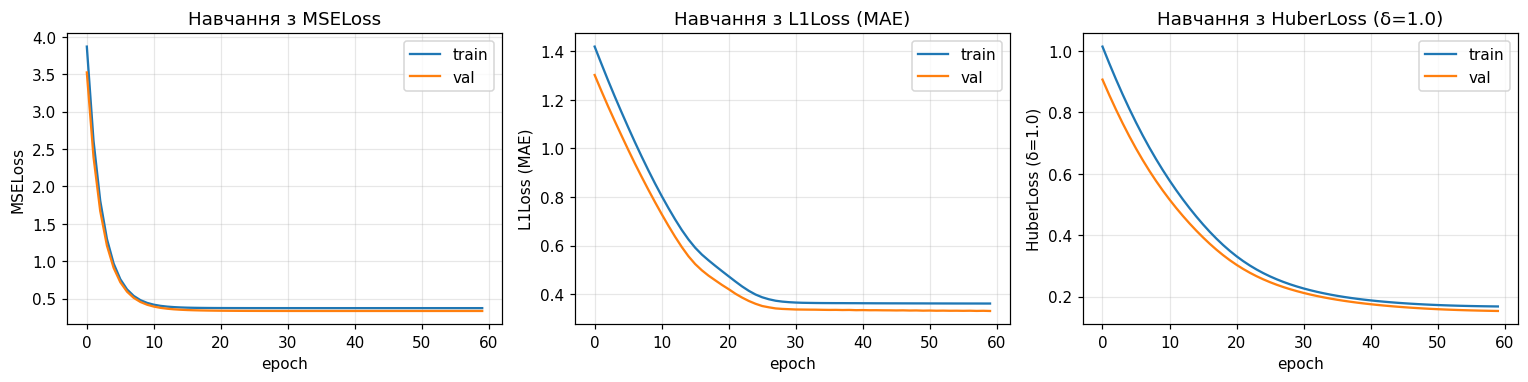

In [6]:
# 0.6. Експеримент (до питання 2): вплив вибору функції втрат (MSELoss, L1Loss, HuberLoss)
# на тренування лінійної регресії
set_seed(SEED)

# Використаємо табличні дані (у масштабі 1 од. = $10,000, аналогічно до масштабу MedHouseVal у демо)
raw_ds = load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")
df_demo = raw_ds["train"].to_pandas()
df_demo["sex"] = df_demo["sex"].map({"female": 0.0, "male": 1.0})
df_demo["smoker"] = df_demo["smoker"].map({"no": 0.0, "yes": 1.0})
df_demo = pd.get_dummies(df_demo, columns=["region"], drop_first=True, dtype=float)

tr_d, tmp_d = train_test_split(df_demo, test_size=0.4, random_state=SEED)
va_d, te_d = train_test_split(tmp_d, test_size=0.5, random_state=SEED)

f_cols = [c for c in tr_d.columns if c != "charges"]
sc_demo = StandardScaler()
X_tr_d = torch.tensor(sc_demo.fit_transform(tr_d[f_cols]), dtype=torch.float32)
X_va_d = torch.tensor(sc_demo.transform(va_d[f_cols]), dtype=torch.float32)
X_te_d = torch.tensor(sc_demo.transform(te_d[f_cols]), dtype=torch.float32)

y_tr_d = torch.tensor(tr_d["charges"].values / 10000.0, dtype=torch.float32).unsqueeze(1)
y_va_d = torch.tensor(va_d["charges"].values / 10000.0, dtype=torch.float32).unsqueeze(1)
y_te_np = te_d["charges"].values / 10000.0

loss_functions = {
    "MSELoss": torch.nn.MSELoss(),
    "L1Loss (MAE)": torch.nn.L1Loss(),
    "HuberLoss (δ=1.0)": torch.nn.HuberLoss(delta=1.0),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
print("Порівняння функцій втрат при тренуванні лінійної регресії (оцінка на test):")

for idx, (lname, criterion) in enumerate(loss_functions.items()):
    set_seed(SEED)
    lin_m = torch.nn.Linear(X_tr_d.shape[1], 1)
    opt = torch.optim.SGD(lin_m.parameters(), lr=0.1)
    tr_hist, va_hist = [], []
    for ep in range(60):
        lin_m.train()
        opt.zero_grad()
        loss = criterion(lin_m(X_tr_d), y_tr_d)
        loss.backward()
        opt.step()
        tr_hist.append(loss.item())
        lin_m.eval()
        with torch.no_grad():
            va_hist.append(criterion(lin_m(X_va_d), y_va_d).item())

    axes[idx].plot(tr_hist, label="train")
    axes[idx].plot(va_hist, label="val")
    axes[idx].set_title(f"Навчання з {lname}")
    axes[idx].set_xlabel("epoch"); axes[idx].set_ylabel(lname)
    axes[idx].legend(); axes[idx].grid(alpha=0.3)

    lin_m.eval()
    with torch.no_grad():
        preds = lin_m(X_te_d).numpy().flatten()
    mse_v = mean_squared_error(y_te_np, preds)
    rmse_v = mse_v ** 0.5
    mae_v = mean_absolute_error(y_te_np, preds)
    r2_v = r2_score(y_te_np, preds)
    print(f"{lname:18s} -> MSE={mse_v:.4f}  RMSE={rmse_v:.4f}  MAE={mae_v:.4f}  R2={r2_v:.4f}")

plt.tight_layout()
plt.show()

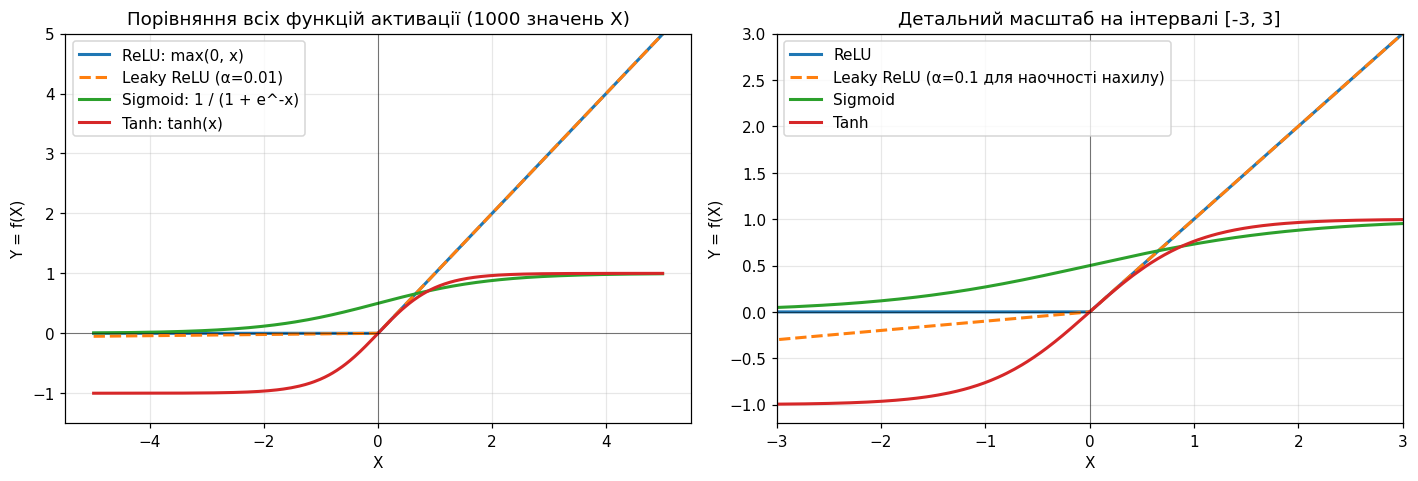

In [7]:
# 0.7. Демонстрація (до питання 5): дія функцій активації на 1000 випадкових значеннях X
rng_act = np.random.default_rng(SEED)
x_rand = np.sort(rng_act.uniform(-5.0, 5.0, 1000)).astype(np.float32)
x_tensor = torch.tensor(x_rand)

y_relu = torch.nn.ReLU()(x_tensor).numpy()
y_leaky_001 = torch.nn.LeakyReLU(negative_slope=0.01)(x_tensor).numpy()
y_leaky_010 = torch.nn.LeakyReLU(negative_slope=0.10)(x_tensor).numpy()
y_sigmoid = torch.nn.Sigmoid()(x_tensor).numpy()
y_tanh = torch.nn.Tanh()(x_tensor).numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(x_rand, y_relu, label="ReLU: max(0, x)", lw=2)
axes[0].plot(x_rand, y_leaky_001, label="Leaky ReLU (α=0.01)", lw=2, linestyle="--")
axes[0].plot(x_rand, y_sigmoid, label="Sigmoid: 1 / (1 + e^-x)", lw=2)
axes[0].plot(x_rand, y_tanh, label="Tanh: tanh(x)", lw=2)
axes[0].axhline(0, color="black", lw=0.7, alpha=0.5)
axes[0].axvline(0, color="black", lw=0.7, alpha=0.5)
axes[0].set_title("Порівняння всіх функцій активації (1000 значень X)")
axes[0].set_xlabel("X"); axes[0].set_ylabel("Y = f(X)")
axes[0].set_ylim(-1.5, 5.0)
axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(x_rand, y_relu, label="ReLU", lw=2)
axes[1].plot(x_rand, y_leaky_010, label="Leaky ReLU (α=0.1 для наочності нахилу)", lw=2, linestyle="--")
axes[1].plot(x_rand, y_sigmoid, label="Sigmoid", lw=2)
axes[1].plot(x_rand, y_tanh, label="Tanh", lw=2)
axes[1].axhline(0, color="black", lw=0.7, alpha=0.5)
axes[1].axvline(0, color="black", lw=0.7, alpha=0.5)
axes[1].set_xlim(-3.0, 3.0); axes[1].set_ylim(-1.2, 3.0)
axes[1].set_title("Детальний масштаб на інтервалі [-3, 3]")
axes[1].set_xlabel("X"); axes[1].set_ylabel("Y = f(X)")
axes[1].grid(alpha=0.3); axes[1].legend()

plt.tight_layout()
plt.show()

In [8]:
# 0.8. Перевірка підрахунку кількості параметрів (до питання 6)
n_feat_demo = 7  # MedInc, HouseAge, AveRooms, Population, AveOccup, diag_coord, bedperroom
demo_nn = torch.nn.Sequential(
    torch.nn.Linear(n_feat_demo, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
)
demo_lin = torch.nn.Linear(n_feat_demo, 1)

print(f"Пошаровий розрахунок параметрів housing_nn (n_features = {n_feat_demo}):")
print(f"  Linear(7 -> 64):   7 * 64 + 64 = {7*64 + 64}")
print(f"  ReLU():            0")
print(f"  Linear(64 -> 32):  64 * 32 + 32 = {64*32 + 32}")
print(f"  ReLU():            0")
print(f"  Linear(32 -> 1):   32 * 1 + 1 = {32*1 + 1}")
nn_p = sum(p.numel() for p in demo_nn.parameters())
lin_p = sum(p.numel() for p in demo_lin.parameters())
print("Кількість параметрів NN:      ", nn_p)
print("Кількість параметрів лінійної:", lin_p)
print(f"Співвідношення (NN / Linear):  {nn_p / lin_p:.2f}x")

Пошаровий розрахунок параметрів housing_nn (n_features = 7):
  Linear(7 -> 64):   7 * 64 + 64 = 512
  ReLU():            0
  Linear(64 -> 32):  64 * 32 + 32 = 2080
  ReLU():            0
  Linear(32 -> 1):   32 * 1 + 1 = 33
Кількість параметрів NN:       2625
Кількість параметрів лінійної: 8
Співвідношення (NN / Linear):  328.12x

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [9]:
DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Бондар Віталій Олександрович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#9): Medical Insurance Cost

---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

### 2.1. Підготовка даних
#### 2.1.1. Завантаження датасету Medical Insurance Cost (#9) і перетворення на DataFrame
Завантажуємо датасет `harishsohani/medical-insurance-cost-prediction` з Hugging Face Hub, явно вказуючи файл `data_files="insurance.csv"` (згідно з інструкцією до датасету #9).

In [10]:
HF_REPO_ID = "harishsohani/medical-insurance-cost-prediction"
insurance_dataset = load_dataset(HF_REPO_ID, data_files="insurance.csv")
print(insurance_dataset)

insurance_df = insurance_dataset["train"].to_pandas()
print("\nЗагальний розмір таблиці:", insurance_df.shape)

DatasetDict({
    train: Dataset({
        features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
        num_rows: 1338
    })
})

Загальний розмір таблиці: (1338, 7)

#### 2.1.2. Спліт даних на `train` / `val` / `test`
**Чому спліт робимо одразу до будь-якого аналізу?**
Якщо рахувати середні значення, межі викидів чи кореляції на всьому датасеті, інформація з тестової вибірки потрапить у навчання (**витік даних / data leakage**), і оцінка якості на `test` буде нечесною. Тому одразу ділимо дані у пропорції **60% train / 20% val / 20% test**, а всі рішення приймаємо тільки на основі `train_df`.

In [11]:
train_df, temp_df = train_test_split(insurance_df, test_size=0.4, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"Розмір навчальної вибірки (train): {train_df.shape}")
print(f"Розмір валідаційної вибірки (val): {val_df.shape}")
print(f"Розмір тестової вибірки (test):   {test_df.shape}")

Розмір навчальної вибірки (train): (802, 7)
Розмір валідаційної вибірки (val): (268, 7)
Розмір тестової вибірки (test):   (268, 7)

#### 2.1.3. Загальний огляд даних (`head`, `info`, `describe`)
Переглядаємо структуру `train_df`: типи колонок, наявність числових і категоріальних ознак та описову статистику.

In [12]:
print("Перші 5 рядків train_df:")
print(train_df.head().to_string())
print("\nІнформація про колонки train_df:")
print(train_df.info())

Перші 5 рядків train_df:
      age     sex    bmi  children smoker     region     charges
25     59  female  27.72         3     no  southeast  14001.1338
336    60    male  25.74         0     no  southeast  12142.5786
47     28  female  34.77         0     no  northwest   3556.9223
106    19  female  28.40         1     no  southwest   2331.5190
1269   45    male  27.50         3     no  southwest   8615.3000

Інформація про колонки train_df:
<class 'pandas.core.frame.DataFrame'>
Index: 802 entries, 25 to 1126
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       802 non-null    int64  
 1   sex       802 non-null    object 
 2   bmi       802 non-null    float64
 3   children  802 non-null    int64  
 4   smoker    802 non-null    object 
 5   region    802 non-null    object 
 6   charges   802 non-null    float64
dtypes: float64(2), int64(2), object(3)
memory usage: 50.1+ KB
None

In [13]:
print("Статистика числових ознак (train_df):")
print(train_df.describe().round(2).to_string())
print("\nСтатистика категоріальних ознак (train_df):")
print(train_df.describe(include="object").to_string())

Статистика числових ознак (train_df):
          age     bmi  children   charges
count  802.00  802.00     802.0    802.00
mean    39.25   30.42       1.1  13297.76
std     14.23    5.97       1.2  12040.60
min     18.00   15.96       0.0   1121.87
25%     27.00   26.18       0.0   4828.59
50%     39.00   30.13       1.0   9502.44
75%     52.00   34.42       2.0  16791.38
max     64.00   53.13       5.0  62592.87

Статистика категоріальних ознак (train_df):
         sex smoker     region
count    802    802        802
unique     2      2          4
top     male     no  southeast
freq     408    634        211

#### 2.1.4. Перевірка та обробка пропусків
Перевіряємо наявність пропущених значень (`NaN` / `null`) у `train_df`, `val_df` та `test_df`.

In [14]:
print("Кількість пропусків у train_df за колонками:")
print(train_df.isna().sum())
print("\nУсього пропусків у train:", train_df.isna().sum().sum())
print("Усього пропусків у val:  ", val_df.isna().sum().sum())
print("Усього пропусків у test: ", test_df.isna().sum().sum())

Кількість пропусків у train_df за колонками:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Усього пропусків у train: 0
Усього пропусків у val:   0
Усього пропусків у test:  0

**Висновок щодо пропусків:** У датасеті немає жодного пропуску (всі комірки в `train_df`, `val_df` і `test_df` заповнені), тому імпутація чи видалення рядків не потрібні.

#### 2.1.5. Розвідувальний аналіз даних (EDA)
Побудуємо одновимірні гістограми для числових ознак (`age`, `bmi`, `children`, `charges`), розподіли категоріальних ознак (`sex`, `smoker`, `region`), а також двовимірну діаграму розсіювання `BMI × Smoker → Charges` та кореляційну матрицю.

Коефіцієнти асиметрії (Skewness) числових колонок train_df:
  age       : 0.047
  bmi       : 0.275
  children  : 0.919
  charges   : 1.544

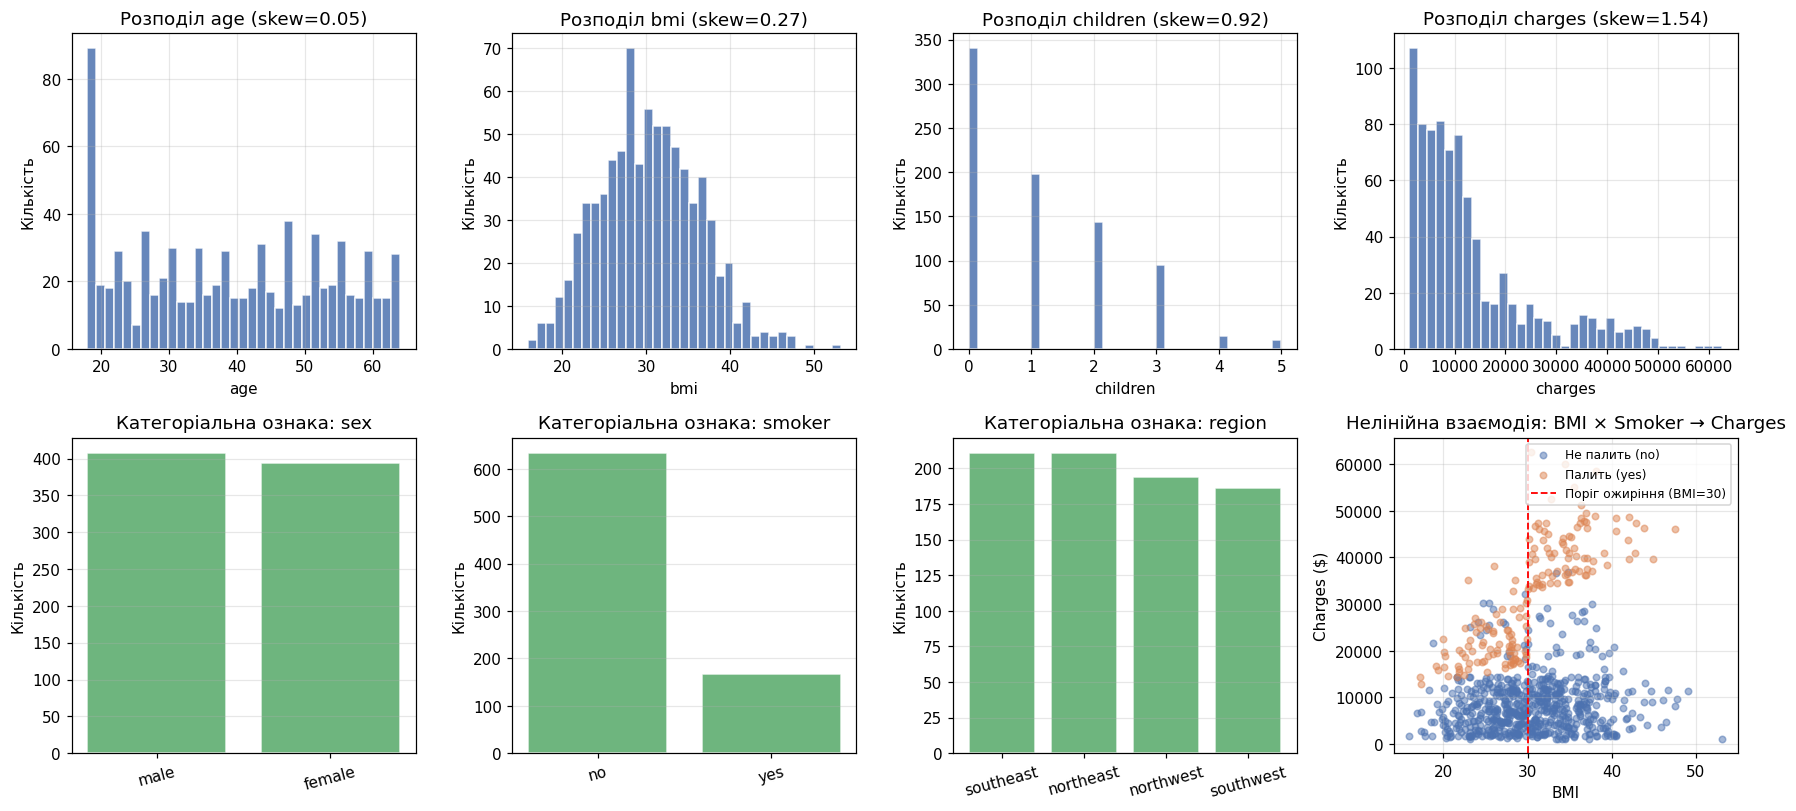

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

num_cols = ["age", "bmi", "children", "charges"]
for i, col in enumerate(num_cols):
    axes[0, i].hist(train_df[col], bins=35, color="#4C72B0", edgecolor="white", alpha=0.85)
    axes[0, i].set_title(f"Розподіл {col} (skew={skew(train_df[col]):.2f})")
    axes[0, i].set_xlabel(col); axes[0, i].set_ylabel("Кількість")
    axes[0, i].grid(alpha=0.3)

cat_cols = ["sex", "smoker", "region"]
for i, col in enumerate(cat_cols):
    vc = train_df[col].value_counts()
    axes[1, i].bar(vc.index.astype(str), vc.values, color="#55A868", edgecolor="white", alpha=0.85)
    axes[1, i].set_title(f"Категоріальна ознака: {col}")
    axes[1, i].set_ylabel("Кількість")
    axes[1, i].tick_params(axis="x", rotation=15)
    axes[1, i].grid(axis="y", alpha=0.3)

for smk_val, color, lbl in [("no", "#4C72B0", "Не палить (no)"), ("yes", "#DD8452", "Палить (yes)")]:
    sub = train_df[train_df["smoker"] == smk_val]
    axes[1, 3].scatter(sub["bmi"], sub["charges"], alpha=0.5, s=18, color=color, label=lbl)
axes[1, 3].axvline(30.0, color="red", linestyle="--", lw=1.2, label="Поріг ожиріння (BMI=30)")
axes[1, 3].set_title("Нелінійна взаємодія: BMI × Smoker → Charges")
axes[1, 3].set_xlabel("BMI"); axes[1, 3].set_ylabel("Charges ($)")
axes[1, 3].legend(fontsize=8)
axes[1, 3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Коефіцієнти асиметрії (Skewness) числових колонок train_df:")
for col in num_cols:
    print(f"  {col:10s}: {skew(train_df[col]):.3f}")

Кореляція ознак із цільовою змінною charges:
charges             1.000
smoker              0.777
age                 0.294
bmi                 0.186
children            0.079
sex                 0.052
region_southeast    0.021
region_southwest   -0.015
region_northwest   -0.028
Name: charges, dtype: float64

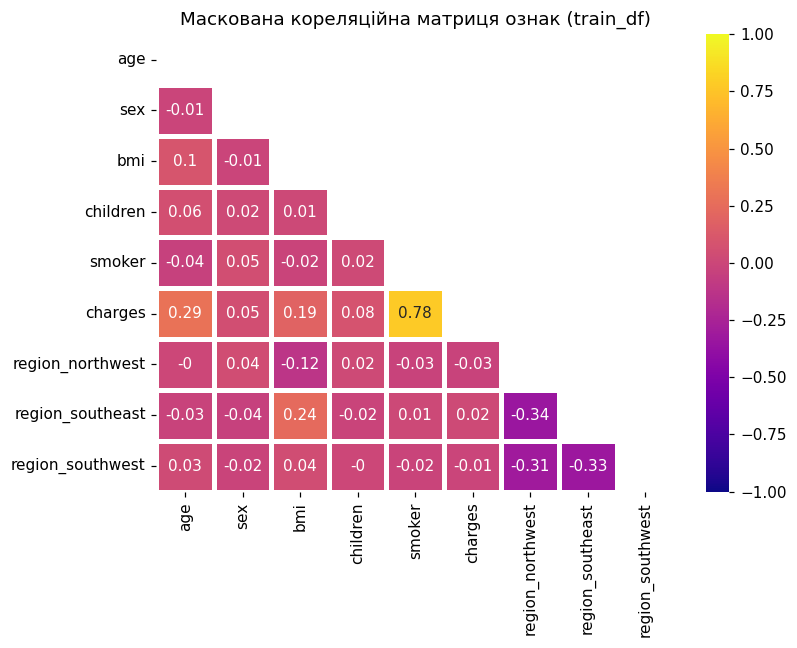

In [16]:
# Для побудови кореляційної матриці закодуємо категоріальні ознаки (sex, smoker, region) у числові
def encode_categoricals(d):
    d = d.copy()
    d["sex"] = d["sex"].map({"female": 0.0, "male": 1.0})
    d["smoker"] = d["smoker"].map({"no": 0.0, "yes": 1.0})
    d = pd.get_dummies(d, columns=["region"], drop_first=True, dtype=float)
    return d

train_encoded = encode_categoricals(train_df)

corr = train_encoded.corr().round(2)
fig, ax = plt.subplots(figsize=(7.5, 6))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, center=0,
            cmap="plasma", square=False, lw=2, annot=True, cbar=True, ax=ax)
ax.set_title("Маскована кореляційна матриця ознак (train_df)")
plt.tight_layout()
plt.show()

print("Кореляція ознак із цільовою змінною charges:")
print(train_encoded.corr()["charges"].sort_values(ascending=False).round(3))

**Основні спостереження після EDA:**
1. **Вік (`age`):** рівномірно розподілений від **18 до 64 років** без штучних обмежень (у США з 65 років діє державна страховка Medicare).
2. **Розподіл `charges` і `bmi`:** цільова змінна `charges` сильно скошена праворуч (більшість платить до $15 000, але є випадки до $62 593). Індекс маси тіла `bmi` має близький до нормального розподіл навколо середнього ~30.4.
3. **Кореляції та нелінійність:**
   - Найбільше на вартість страховки впливає куріння **`smoker` ($r = 0.78$)**, далі йдуть **`age` ($r = 0.29$)** та **`bmi` ($r = 0.19$)**.
   - Ознаки **`sex`** та **`region`** мають майже нульову кореляцію з виплатами ($|r| \le 0.05$).
   - На графіку `BMI × Smoker → Charges` добре видно **нелінійний ефект**: у некурців витрати ростуть повільно незалежно від ваги, а у курців із ожирінням (**$\text{BMI} \ge 30$**) вартість страховки різко стрибає з ~$20 000 до **$35 000 – $62 000**. Саме для такої нелінійної взаємодії нейромережа підходить набагато краще за лінійну регресію.

#### 2.1.6. Аналіз та обробка викидів (Outliers)
Перевіримо числові ознаки на наявність статистичних викидів за правилом міжквартильного розмаху ($Q_3 + 1.5 \times \text{IQR}$) у `train_df`.

In [17]:
q1_bmi, q3_bmi = train_df["bmi"].quantile([0.25, 0.75])
iqr_bmi = q3_bmi - q1_bmi
upper_bound_bmi = q3_bmi + 1.5 * iqr_bmi

bmi_outliers = train_df[train_df["bmi"] > upper_bound_bmi]
print(f"BMI: Q1 = {q1_bmi:.2f}, Q3 = {q3_bmi:.2f}, IQR = {iqr_bmi:.2f}, Верхня межа (Q3 + 1.5*IQR) = {upper_bound_bmi:.2f}")
print(f"Кількість рядків із BMI > {upper_bound_bmi:.2f} у train_df: {len(bmi_outliers)}")
print(bmi_outliers[["age", "sex", "bmi", "children", "smoker", "charges"]].to_string())

BMI: Q1 = 26.18, Q3 = 34.42, IQR = 8.24, Верхня межа (Q3 + 1.5*IQR) = 46.79
Кількість рядків із BMI > 46.79 у train_df: 5
      age     sex    bmi  children smoker     charges
1088   52    male  47.74         1     no   9748.9106
1317   18    male  53.13         0     no   1163.4627
116    58    male  49.06         0     no  11381.3254
401    47    male  47.52         1     no   8083.9198
860    37  female  47.60         2    yes  46113.5110

**Рішення щодо викидів:**
- У `train_df` є лише 5 рядків із високим $\text{BMI}$ ($47.5\text{–}53.1$). Це не помилки в даних, а реальні медичні випадки сильного ожиріння, і їхні страхові виплати повністю логічні.
- Оскільки це справжні спостереження, а не збій запису, **залишаємо всі рядки**, щоб модель навчилася працювати з такими пацієнтами.

#### 2.1.7. Інженерія ознак (Feature Engineering)
За результатами EDA та матриці кореляцій у `train_df` виконуємо два кроки (за аналогією з п. 1.8.3 демо):
1. **Додаємо бінарну ознаку ожиріння `is_obese` ($\text{BMI} \ge 30$):** саме після клінічного порогу $\text{BMI} = 30$ у курців різко зростають страхові витрати. Нова ознака має вищу лінійну кореляцію з `charges` ($r = 0.204$), ніж сам безперервний `bmi` ($r = 0.186$), і допомагає моделям точніше вловити цей пороговий стрибок.
2. **Прибираємо шумові ознаки `sex` та `region_*`:** за кореляційною матрицею на `train_df` їхній зв'язок із цільовою змінною близький до нуля (`sex`: $r = 0.052$; `region_southeast`: $r = 0.021$; `region_southwest`: $r = -0.015$; `region_northwest`: $r = -0.028$). Вони не несуть корисного сигналу, а лише додають зайві виміри, тому видаляємо їх і залишаємо 5 інформативних числових ознак: `['age', 'bmi', 'children', 'smoker', 'is_obese']`.

In [18]:
def prepare_features(d):
    d = encode_categoricals(d)
    # 1. Нова ознака: клінічний поріг ожиріння (BMI >= 30)
    d["is_obese"] = (d["bmi"] >= 30.0).astype(float)
    # 2. Видаляємо ознаки з майже нульовою кореляцією з таргетом (|r| <= 0.05)
    d.drop(columns=["sex", "region_northwest", "region_southeast", "region_southwest"], inplace=True)
    return d

train_df = prepare_features(train_df)
val_df = prepare_features(val_df)
test_df = prepare_features(test_df)

print("Колонки після інженерії ознак:", list(train_df.columns))
print("\nКореляція фінальних ознак із charges (на train_df):")
print(train_df.corr()["charges"].sort_values(ascending=False).round(3))

Колонки після інженерії ознак: ['age', 'bmi', 'children', 'smoker', 'charges', 'is_obese']

Кореляція фінальних ознак із charges (на train_df):
charges     1.000
smoker      0.777
age         0.294
is_obese    0.204
bmi         0.186
children    0.079
Name: charges, dtype: float64

---
### 2.2. Baseline: множинна лінійна регресія (Варіант #1 — `linear`)
Виконуємо стандартизацію ознак через `StandardScaler` (навчаємо `fit_transform` **виключно на `train_df`**, а до `val_df` і `test_df` застосовуємо `transform`), конвертуємо дані у тензори PyTorch та тренуємо базову лінійну регресію `nn.Linear(5, 1)`.

In [19]:
feature_cols = [c for c in train_df.columns if c != "charges"]

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols])  # fit + transform тільки на train
X_val = scaler.transform(val_df[feature_cols])          # лише transform на val
X_test = scaler.transform(test_df[feature_cols])        # лише transform на test

y_train = train_df["charges"].values
y_val = val_df["charges"].values
y_test = test_df["charges"].values

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device),
    )

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

print(f"Ознаки ({len(feature_cols)}):", feature_cols)
print("Форма X_train:", X_train.shape)
print()

set_seed(SEED)
n_features = X_train.shape[1]
linear_model = torch.nn.Linear(in_features=n_features, out_features=1).to(device)
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.1)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "linear"))

N_EPOCHS_LIN = 40
lin_train_losses, lin_val_losses = [], []

for epoch in range(N_EPOCHS_LIN):
    linear_model.train()
    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    lin_train_losses.append(loss.item())

    linear_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(linear_model(x_val_t), y_val_t).item()
    lin_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 5 == 0 or epoch == N_EPOCHS_LIN - 1:
        print(f"epoch {epoch:4d}  train_loss={loss.item():12.2f}  val_loss={val_loss:12.2f}")

writer.close()
torch.save(linear_model.state_dict(), os.path.join(MODELS_DIR, "linear.pt"))

Ознаки (5): ['age', 'bmi', 'children', 'smoker', 'is_obese']
Форма X_train: (802, 5)

epoch    0  train_loss=321632416.00  val_loss=195532928.00
epoch    5  train_loss= 66936180.00  val_loss= 52058260.00
epoch   10  train_loss= 39622992.00  val_loss= 36556020.00
epoch   15  train_loss= 36581640.00  val_loss= 34803476.00
epoch   20  train_loss= 36221724.00  val_loss= 34632056.00
epoch   25  train_loss= 36166984.00  val_loss= 34658992.00
epoch   30  train_loss= 36151208.00  val_loss= 34711532.00
epoch   35  train_loss= 36142992.00  val_loss= 34763292.00
epoch   39  train_loss= 36138632.00  val_loss= 34800532.00

Конст. бейзлайн   MSE=156133552.0000  RMSE=12495.3412  MAE=9475.2461  R2=-0.0066
linear            MSE=36739188.0000  RMSE=6061.2860  MAE=4476.2075  R2=0.7631

Ваги стандартизованих ознак у лінійній регресії:
 feature      weight
  smoker 9549.254883
     age 3679.216309
is_obese 1790.359741
     bmi  599.878296
children  537.621948

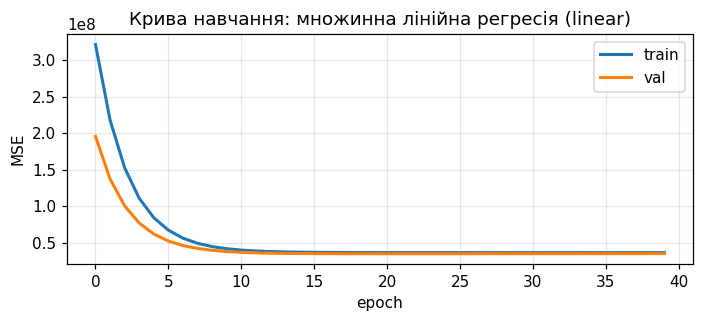

In [20]:
plt.figure(figsize=(6.5, 3.2))
plt.plot(lin_train_losses, label="train", lw=2)
plt.plot(lin_val_losses, label="val", lw=2)
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: множинна лінійна регресія (linear)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

def evaluate_predictions(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:16s}  MSE={mse:12.4f}  RMSE={rmse:9.4f}  MAE={mae:9.4f}  R2={r2:.4f}")
    return {"model": name, "MSE": round(mse, 4), "RMSE": round(rmse, 4), "MAE": round(mae, 4), "R2": round(r2, 4)}

linear_model.eval()
with torch.no_grad():
    y_test_pred_lin = linear_model(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())
evaluate_predictions(y_test, baseline_pred, "Конст. бейзлайн")
res_linear = evaluate_predictions(y_test, y_test_pred_lin, "linear")

weights = linear_model.weight.detach().cpu().numpy().flatten()
weight_df = pd.DataFrame({"feature": feature_cols, "weight": weights})
weight_df["abs_weight"] = weight_df["weight"].abs()
weight_df = weight_df.sort_values("abs_weight", ascending=False).drop(columns="abs_weight")
print("\nВаги стандартизованих ознак у лінійній регресії:")
print(weight_df.to_string(index=False))

**Результати лінійної регресії (`linear`):**
- Модель суттєво перевершує константний baseline: $R^2$ зріс із `-0.0066` до **`0.7631`**, а помилка RMSE зменшилася більш ніж удвічі — з `$12 495.34` до **`$6 061.29`**.
- Ваги стандартизованих ознак повністю узгоджуються з EDA: найбільший вплив має куріння **`smoker` (`+9549.25`)**, далі йдуть вік **`age` (`+3679.22`)** і наша нова ознака **`is_obese` (`+1790.36`)**, яка має більшу вагу, ніж сам безперервний **`bmi` (`+599.88`)**. Найменший, але додатний внесок має кількість дітей **`children` (`+537.62`)**.

---
### 2.3. Нейромережа: порівняння 3 різних архітектур (`nn_v1`, `nn_v2`, `nn_v3`)
Протестуємо **3 різні архітектури** з однаковими базовими налаштуваннями (`Adam`, `lr = 0.05`, `200` епох, full-batch):
1. **`nn_v1` (Варіант #2)**: двошарова мережа з демо `5 → 64 → 32 → 1` з `ReLU` (`2 497` параметрів).
2. **`nn_v2` (Варіант #3)**: глибша тришарова мережа `5 → 128 → 64 → 32 → 1` з `LeakyReLU` (`11 137` параметрів).
3. **`nn_v3` (Варіант #4)**: компактна вузька мережа `5 → 32 → 16 → 1` з `ReLU` (`737` параметрів).

=== Тренування nn_v1 (NN v1: 5→64→32→1, ReLU (Adam, lr=0.05, 200 епох), параметрів: 2497) ===
  epoch    0: train_loss=321625184.00  val_loss=288430112.00
  epoch  100: train_loss= 23726664.00  val_loss= 23249140.00
  epoch  199: train_loss= 19510104.00  val_loss= 19191500.00
nn_v1             MSE=21053428.0000  RMSE=4588.4015  MAE=2555.6985  R2=0.8643

=== Тренування nn_v2 (NN v2: 5→128→64→32→1, LeakyReLU (Adam, lr=0.05, 200 епох), параметрів: 11137) ===
  epoch    0: train_loss=321627616.00  val_loss=288363520.00
  epoch  100: train_loss= 19528924.00  val_loss= 19275494.00
  epoch  199: train_loss= 19274386.00  val_loss= 19122272.00
nn_v2             MSE=20710404.0000  RMSE=4550.8685  MAE=2531.5498  R2=0.8665

=== Тренування nn_v3 (NN v3: 5→32→16→1, ReLU (Adam, lr=0.05, 200 епох), параметрів: 737) ===
  epoch    0: train_loss=321623584.00  val_loss=288455360.00
  epoch  100: train_loss= 29054736.00  val_loss= 27955436.00
  epoch  199: train_loss= 20743198.00  val_loss= 20246960.00
nn

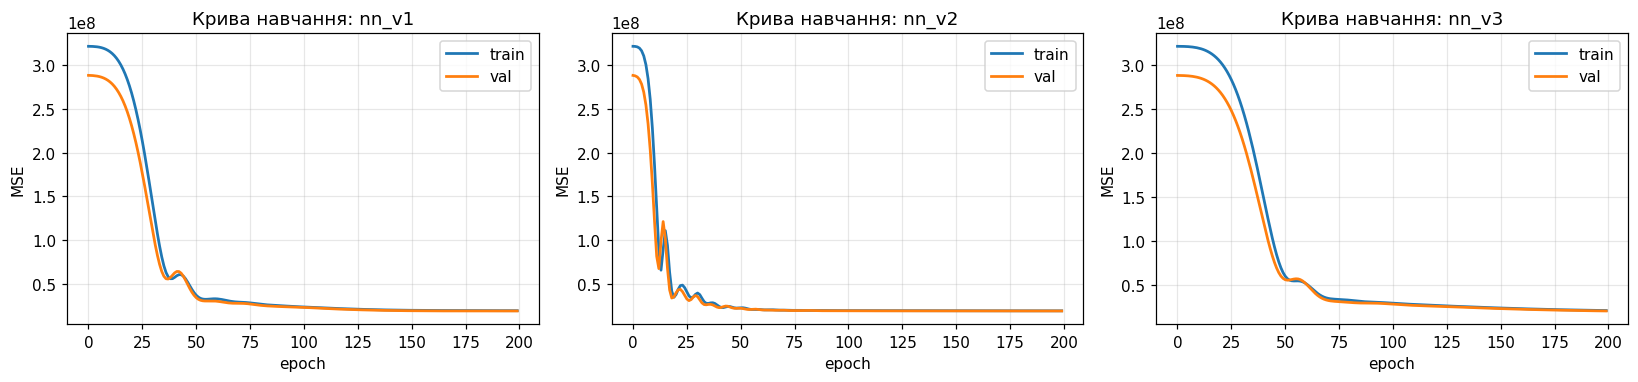

In [21]:
def build_nn_v1(in_features):
    return torch.nn.Sequential(
        torch.nn.Linear(in_features, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 1),
    )

def build_nn_v2(in_features):
    return torch.nn.Sequential(
        torch.nn.Linear(in_features, 128),
        torch.nn.LeakyReLU(negative_slope=0.01),
        torch.nn.Linear(128, 64),
        torch.nn.LeakyReLU(negative_slope=0.01),
        torch.nn.Linear(64, 32),
        torch.nn.LeakyReLU(negative_slope=0.01),
        torch.nn.Linear(32, 1),
    )

def build_nn_v3(in_features):
    return torch.nn.Sequential(
        torch.nn.Linear(in_features, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 1),
    )

def train_and_log_nn(model_name, model_fn, lr=0.05, epochs=200, opt_type="adam", batch_size=None, desc=""):
    set_seed(SEED)
    model = model_fn(n_features).to(device)
    if opt_type == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    elif opt_type == "rmsprop":
        opt = torch.optim.RMSprop(model.parameters(), lr=lr, alpha=0.99)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr)

    criterion = torch.nn.MSELoss()
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, model_name))
    tr_losses, va_losses = [], []
    n_total = x_train_t.shape[0]
    bs = n_total if batch_size is None else batch_size

    for ep in range(epochs):
        model.train()
        if batch_size is not None:
            perm = torch.randperm(n_total, device=device)
        else:
            perm = torch.arange(n_total, device=device)

        ep_batch_losses = []
        for start in range(0, n_total, bs):
            idx = perm[start:start + bs]
            xb, yb = x_train_t[idx], y_train_t[idx]
            opt.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            opt.step()
            ep_batch_losses.append(loss.item())

        tr_loss_ep = float(np.mean(ep_batch_losses))
        model.eval()
        with torch.no_grad():
            va_loss_ep = criterion(model(x_val_t), y_val_t).item()

        tr_losses.append(tr_loss_ep)
        va_losses.append(va_loss_ep)
        writer.add_scalar("Loss/train", tr_loss_ep, ep)
        writer.add_scalar("Loss/val", va_loss_ep, ep)

    writer.close()
    torch.save(model.state_dict(), os.path.join(MODELS_DIR, f"{model_name}.pt"))

    n_params = sum(p.numel() for p in model.parameters())
    print(f"=== Тренування {model_name} ({desc}, параметрів: {n_params}) ===")
    print(f"  epoch    0: train_loss={tr_losses[0]:12.2f}  val_loss={va_losses[0]:12.2f}")
    print(f"  epoch  {epochs//2:3d}: train_loss={tr_losses[epochs//2]:12.2f}  val_loss={va_losses[epochs//2]:12.2f}")
    print(f"  epoch  {epochs-1:3d}: train_loss={tr_losses[-1]:12.2f}  val_loss={va_losses[-1]:12.2f}")

    model.eval()
    with torch.no_grad():
        test_preds = model(x_test_t).cpu().numpy().flatten()
    metrics = evaluate_predictions(y_test, test_preds, model_name)
    print()
    return model, tr_losses, va_losses, metrics

nn_v1_model, v1_tr, v1_va, res_v1 = train_and_log_nn(
    "nn_v1", build_nn_v1, lr=0.05, epochs=200, opt_type="adam",
    desc="NN v1: 5→64→32→1, ReLU (Adam, lr=0.05, 200 епох)"
)
nn_v2_model, v2_tr, v2_va, res_v2 = train_and_log_nn(
    "nn_v2", build_nn_v2, lr=0.05, epochs=200, opt_type="adam",
    desc="NN v2: 5→128→64→32→1, LeakyReLU (Adam, lr=0.05, 200 епох)"
)
nn_v3_model, v3_tr, v3_va, res_v3 = train_and_log_nn(
    "nn_v3", build_nn_v3, lr=0.05, epochs=200, opt_type="adam",
    desc="NN v3: 5→32→16→1, ReLU (Adam, lr=0.05, 200 епох)"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (mname, tr_l, va_l) in zip(axes, [("nn_v1", v1_tr, v1_va), ("nn_v2", v2_tr, v2_va), ("nn_v3", v3_tr, v3_va)]):
    ax.plot(tr_l, label="train", lw=1.8)
    ax.plot(va_l, label="val", lw=1.8)
    ax.set_title(f"Крива навчання: {mname}")
    ax.set_xlabel("epoch"); ax.set_ylabel("MSE")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
### 2.4. Підбір гіперпараметрів на найкращій архітектурі `nn_v2` (4 експерименти)
У п. 2.3 найкраще себе показала тришарова модель **`nn_v2`** ($R^2 = 0.8665$, $\text{RMSE} = 4550.87$). Візьмемо її за основу і по черзі змінимо **по одному гіперпараметру**:
1. **`nn_v2_lr_0.01` (Варіант #5):** зменшуємо `lr` з `0.05` до `0.01`.
2. **`nn_v2_rmsprop` (Варіант #6):** замінюємо оптимізатор `Adam` на `RMSprop(lr=0.05)`.
3. **`nn_v2_epochs_350` (Варіант #7):** збільшуємо кількість епох з `200` до `350`.
4. **`nn_v2_batch_64` (Варіант #8):** переходимо від full-batch до mini-batch навчання (`batch_size = 64`).

=== Тренування nn_v2_lr_0.01 (NN v2 + lr=0.01 (Adam, 200 епох), параметрів: 11137) ===
  epoch    0: train_loss=321627616.00  val_loss=288471680.00
  epoch  100: train_loss= 24094718.00  val_loss= 23445274.00
  epoch  199: train_loss= 19716224.00  val_loss= 19440740.00
nn_v2_lr_0.01     MSE=20947276.0000  RMSE=4576.8194  MAE=2526.5474  R2=0.8650

=== Тренування nn_v2_rmsprop (NN v2 + RMSprop (lr=0.05, 200 епох), параметрів: 11137) ===
  epoch    0: train_loss=321627616.00  val_loss=235235872.00
  epoch  100: train_loss= 21067336.00  val_loss= 20726184.00
  epoch  199: train_loss= 22221526.00  val_loss= 22284128.00
nn_v2_rmsprop     MSE=25721138.0000  RMSE=5071.6011  MAE=3707.2048  R2=0.8342

=== Тренування nn_v2_epochs_350 (NN v2 + 350 епох (Adam, lr=0.05), параметрів: 11137) ===
  epoch    0: train_loss=321627616.00  val_loss=288363520.00
  epoch  175: train_loss= 19308026.00  val_loss= 19141540.00
  epoch  349: train_loss= 19119172.00  val_loss= 19014484.00
nn_v2_epochs_350  MSE=2059

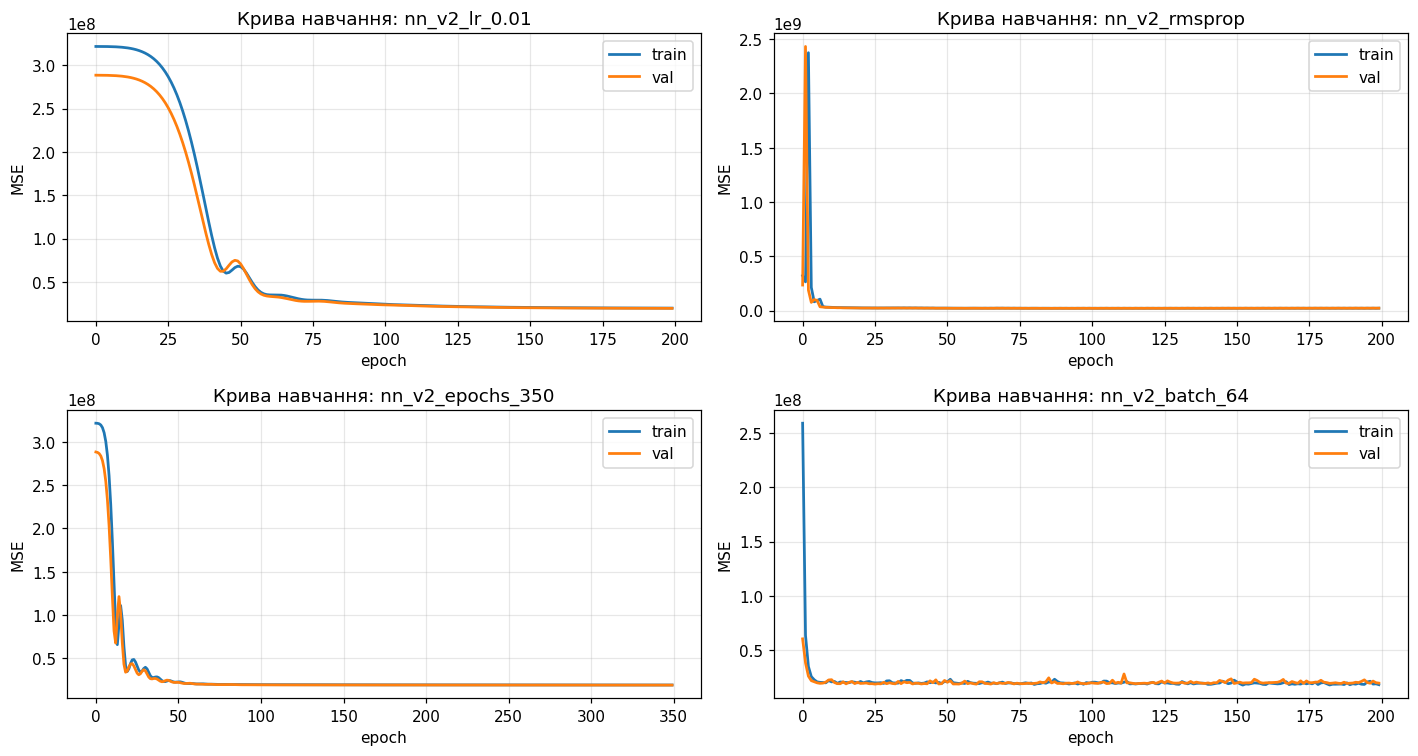

In [22]:
nn_v2_lr_model, hp1_tr, hp1_va, res_hp1 = train_and_log_nn(
    "nn_v2_lr_0.01", build_nn_v2, lr=0.01, epochs=200, opt_type="adam",
    desc="NN v2 + lr=0.01 (Adam, 200 епох)"
)
nn_v2_rms_model, hp2_tr, hp2_va, res_hp2 = train_and_log_nn(
    "nn_v2_rmsprop", build_nn_v2, lr=0.05, epochs=200, opt_type="rmsprop",
    desc="NN v2 + RMSprop (lr=0.05, 200 епох)"
)
nn_v2_ep350_model, hp3_tr, hp3_va, res_hp3 = train_and_log_nn(
    "nn_v2_epochs_350", build_nn_v2, lr=0.05, epochs=350, opt_type="adam",
    desc="NN v2 + 350 епох (Adam, lr=0.05)"
)
nn_v2_bs64_model, hp4_tr, hp4_va, res_hp4 = train_and_log_nn(
    "nn_v2_batch_64", build_nn_v2, lr=0.05, epochs=200, opt_type="adam", batch_size=64,
    desc="NN v2 + batch_size=64 (Adam, lr=0.05, 200 епох)"
)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
hp_runs = [
    ("nn_v2_lr_0.01", hp1_tr, hp1_va),
    ("nn_v2_rmsprop", hp2_tr, hp2_va),
    ("nn_v2_epochs_350", hp3_tr, hp3_va),
    ("nn_v2_batch_64", hp4_tr, hp4_va),
]
for idx, (mname, tr_l, va_l) in enumerate(hp_runs):
    r, c = divmod(idx, 2)
    axes[r, c].plot(tr_l, label="train", lw=1.8)
    axes[r, c].plot(va_l, label="val", lw=1.8)
    axes[r, c].set_title(f"Крива навчання: {mname}")
    axes[r, c].set_xlabel("epoch"); axes[r, c].set_ylabel("MSE")
    axes[r, c].legend(); axes[r, c].grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
### 2.5. Логування в TensorBoard та фінальне порівняння всіх варіантів (`results.csv`)
Усі 8 варіантів моделей записані в окремі підпапки `runs/`. Запускаємо TensorBoard для інтерактивного перегляду, будуємо зведені графіки кривих валідації та $R^2$, а також зберігаємо підсумкову таблицю `results.csv`.

In [23]:
%load_ext tensorboard
%tensorboard --logdir {RUNS_DIR}

Reusing TensorBoard on port 6006 (pid 1842), started 0:00:02 ago. (Use '!kill 1842' to kill it.)

Підсумкова таблиця результатів на тестовій вибірці (збережено у results.csv):
           model        MSE      RMSE       MAE     R2
          linear 36739188.0 6061.2860 4476.2075 0.7631
           nn_v1 21053428.0 4588.4015 2555.6985 0.8643
           nn_v2 20710404.0 4550.8685 2531.5498 0.8665
           nn_v3 21954886.0 4685.6041 2647.2634 0.8585
   nn_v2_lr_0.01 20947276.0 4576.8194 2526.5474 0.8650
   nn_v2_rmsprop 25721138.0 5071.6011 3707.2048 0.8342
nn_v2_epochs_350 20594522.0 4538.1188 2525.4800 0.8672
  nn_v2_batch_64 20731984.0 4553.2388 2462.2639 0.8663

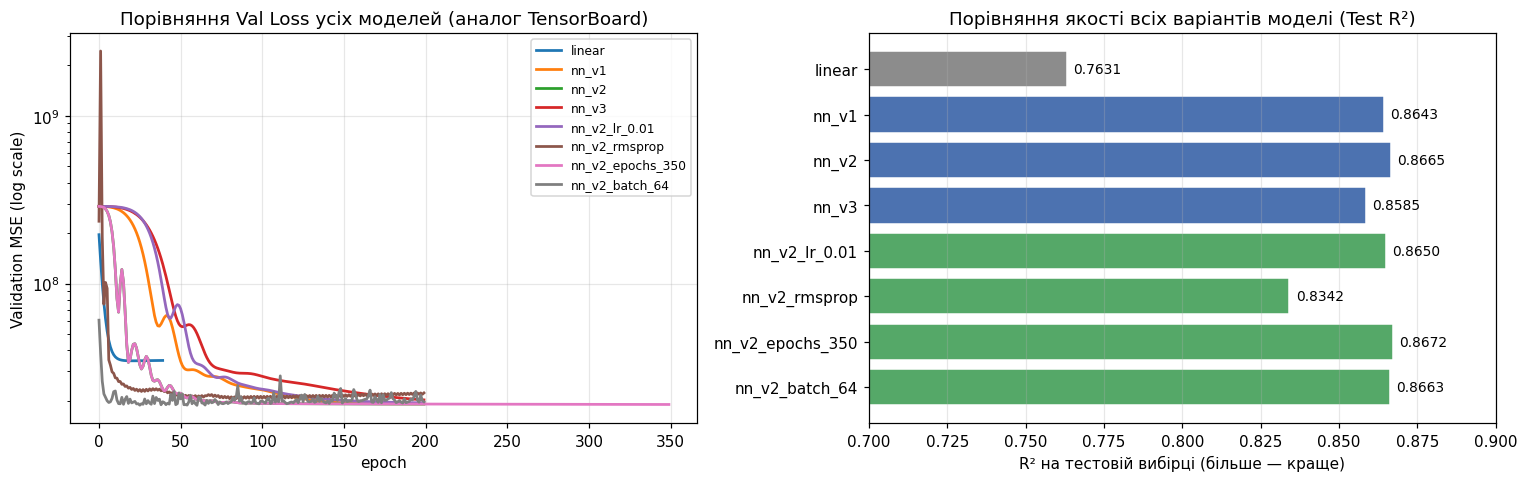

In [24]:
all_results = [res_linear, res_v1, res_v2, res_v3, res_hp1, res_hp2, res_hp3, res_hp4]
results_df = pd.DataFrame(all_results)
results_df.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"), index=False)

print("Підсумкова таблиця результатів на тестовій вибірці (збережено у results.csv):")
print(results_df.to_string(index=False))

# Візуальне накладання всіх валідаційних кривих та порівняння Test R²
all_val_histories = {
    "linear": lin_val_losses,
    "nn_v1": v1_va,
    "nn_v2": v2_va,
    "nn_v3": v3_va,
    "nn_v2_lr_0.01": hp1_va,
    "nn_v2_rmsprop": hp2_va,
    "nn_v2_epochs_350": hp3_va,
    "nn_v2_batch_64": hp4_va,
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for mname, va_hist in all_val_histories.items():
    axes[0].plot(va_hist, label=mname, lw=1.8)
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("Validation MSE (log scale)")
axes[0].set_title("Порівняння Val Loss усіх моделей (аналог TensorBoard)")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

model_labels = results_df["model"].tolist()
r2_vals = results_df["R2"].tolist()
colors_bar = ["#8C8C8C"] + ["#4C72B0"]*3 + ["#55A868"]*4
bars = axes[1].barh(model_labels[::-1], r2_vals[::-1], color=colors_bar[::-1], edgecolor="white")
axes[1].set_xlim(0.70, 0.90)
axes[1].set_xlabel("R² на тестовій вибірці (більше — краще)")
axes[1].set_title("Порівняння якості всіх варіантів моделі (Test R²)")
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 0.002, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", fontsize=9)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

#### Висновки за результатами експериментів (2.5)

##### 1. Яка модель перемогла і наскільки суттєво?

| Модель | MSE ↓ | RMSE (дол.) ↓ | MAE (дол.) ↓ | R² ↑ |
| :--- | ---: | ---: | ---: | ---: |
| `linear` (Baseline) | 36 739 188.0 | 6061.29 | 4476.21 | 0.7631 |
| `nn_v1` (`5→64→32→1`, ReLU) | 21 053 428.0 | 4588.40 | 2555.70 | 0.8643 |
| `nn_v2` (`5→128→64→32→1`, LeakyReLU) | 20 710 404.0 | 4550.87 | 2531.55 | 0.8665 |
| `nn_v3` (`5→32→16→1`, ReLU) | 21 954 886.0 | 4685.60 | 2647.26 | 0.8585 |
| `nn_v2_lr_0.01` | 20 947 276.0 | 4576.82 | 2526.55 | 0.8650 |
| `nn_v2_rmsprop` | 25 721 138.0 | 5071.60 | 3707.20 | 0.8342 |
| **`nn_v2_epochs_350`** | **20 594 522.0** | **4538.12** | 2525.48 | **0.8672** |
| **`nn_v2_batch_64`** | 20 731 984.0 | 4553.24 | **2462.26** | 0.8663 |

- **За MSE (`20 594 522.0`), RMSE (`$4 538.12`) та $R^2$ (`0.8672`) перемогла `nn_v2_epochs_350`** — тришарова мережа `5 → 128 → 64 → 32 → 1` з `LeakyReLU`, оптимізатором `Adam(lr=0.05)` та 350 епохами навчання.
- **За MAE (`$2 462.26`) перемогла `nn_v2_batch_64`** — та сама архітектура з навчанням міні-батчами по 64.
- Відрив від лінійної регресії (`linear`: $\text{RMSE} = \$6 061.29$, $R^2 = 0.7631$) дуже суттєвий: **$R^2$ зріс на +10.41 в.п. (до 86.72%)**, а похибки RMSE та MAE зменшилися на **$1 523.17 (25.1%)** та **$1 950.73 (43.6%)** відповідно.

##### 2. Чи виправдала себе нейромережа порівняно з лінійною регресією?

- **Так, повністю.** Лінійна регресія просто додає вплив ознак окремо і не здатна описати нелінійну комбінацію «курець + ожиріння» ($\text{BMI} \ge 30$), через яку вартість страховки стрибкоподібно зростає. Натомість навіть базова двошарова нейромережа `nn_v1` одразу підняла $R^2$ із **0.7631 до 0.8643**, а найкраща модель довела його до **0.8672**.

##### 3. Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

- **Головний стрибок якості (+10.12 в.п. до $R^2$)** дав сам перехід від лінійної моделі до багатошарової нелінійної мережі (`linear` → `nn_v1`).
- **Серед архітектур (п. 2.3):** розширення й поглиблення мережі до 3 прихованих шарів із `LeakyReLU` (`nn_v2`) дало кращий результат ($R^2 = 0.8665$, $\text{RMSE} = \$4 550.87$), ніж вузька двошарова `nn_v3` ($R^2 = 0.8585$, $\text{RMSE} = \$4 685.60$).
- **Серед гіперпараметрів (п. 2.4):** найбільше вплинув вибір оптимізатора — заміна `Adam` на `RMSprop` без моментуму першого порядку погіршила $R^2$ до `0.8342` ($\text{RMSE} = \$5 071.60$). Натомість збільшення кількості епох до `350` (`nn_v2_epochs_350`) та перехід до `batch_size = 64` (`nn_v2_batch_64`) дозволили покращити фінальні метрики за RMSE/$R^2$ та MAE.

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [25]:
all_models_dict = {
    "linear": linear_model,
    "nn_v1": nn_v1_model,
    "nn_v2": nn_v2_model,
    "nn_v3": nn_v3_model,
    "nn_v2_lr_0.01": nn_v2_lr_model,
    "nn_v2_rmsprop": nn_v2_rms_model,
    "nn_v2_epochs_350": nn_v2_ep350_model,
    "nn_v2_batch_64": nn_v2_bs64_model,
}

def predict_all_models(age, bmi, children, smoker_flag):
    is_obese_val = 1.0 if float(bmi) >= 30.0 else 0.0
    row_df = pd.DataFrame(
        [[float(age), float(bmi), float(children), float(smoker_flag), is_obese_val]],
        columns=feature_cols,
    )
    x_scaled = scaler.transform(row_df)
    x_t = torch.tensor(x_scaled, dtype=torch.float32).to(device)
    preds = {}
    for name, mdl in all_models_dict.items():
        mdl.eval()
        with torch.no_grad():
            preds[name] = mdl(x_t).item()
    return preds

def run_gradio_prediction(selected_model, age, bmi, children, smoker_choice):
    smoker_val = 1.0 if smoker_choice == "Так (1)" else 0.0
    preds = predict_all_models(age, bmi, children, smoker_val)
    selected_pred = round(preds[selected_model], 2)

    fig, ax = plt.subplots(figsize=(8, 3.8))
    colors = ["#E15759" if k == selected_model else "#4C72B0" for k in preds.keys()]
    bars = ax.bar(preds.keys(), preds.values(), color=colors, edgecolor="white")
    ax.set_ylabel("Прогноз charges ($)")
    ax.set_title("Порівняння прогнозів усіх 8 варіантів моделі")
    plt.xticks(rotation=25, ha="right")
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h, f"${h:,.0f}", ha="center", va="bottom", fontsize=8)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    return selected_pred, fig

with gr.Blocks(title="Medical Insurance Cost — Порівняння моделей") as demo:
    gr.Markdown("## Прогноз медичних страхових витрат (Medical Insurance Cost) — порівняння 8 моделей")
    with gr.Row():
        with gr.Column():
            age_slider = gr.Slider(
                minimum=float(train_df["age"].min()),
                maximum=float(train_df["age"].max()),
                value=float(round(train_df["age"].mean())),
                step=1,
                label="Вік (age)",
            )
            bmi_slider = gr.Slider(
                minimum=float(train_df["bmi"].min()),
                maximum=float(train_df["bmi"].max()),
                value=float(round(train_df["bmi"].mean(), 1)),
                step=0.1,
                label="Індекс маси тіла (bmi; ≥30 автоматично встановлює is_obese=1)",
            )
            children_slider = gr.Slider(
                minimum=0,
                maximum=5,
                value=1,
                step=1,
                label="Кількість дітей (children)",
            )
            smoker_radio = gr.Radio(
                choices=["Ні (0)", "Так (1)"],
                value="Ні (0)",
                label="Куріння (smoker)",
            )
            model_dropdown = gr.Dropdown(
                choices=list(all_models_dict.keys()),
                value="nn_v2_epochs_350",
                label="Основна модель для прогнозу",
            )
            submit_btn = gr.Button("Порахувати прогноз", variant="primary")
        with gr.Column():
            prediction_output = gr.Number(label="Прогноз обраної моделі ($)")
            comparison_plot = gr.Plot(label="Порівняння всіх 8 моделей")

    submit_btn.click(
        fn=run_gradio_prediction,
        inputs=[model_dropdown, age_slider, bmi_slider, children_slider, smoker_radio],
        outputs=[prediction_output, comparison_plot],
    )

demo.launch(share=True)

Running on local URL:  http://127.0.0.1:7860
Running on public URL: https://gradio.live/...

---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```